<a href="https://colab.research.google.com/github/universe-sm/UCS420-/blob/main/UCS420_1024160072_A10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Performance Classification Evaluation ===
Accuracy Score: 70.00%

                  precision    recall  f1-score   support

      Prevention       0.50      1.00      0.67         2
    Risk_Factors       1.00      1.00      1.00         2
        Symptoms       1.00      1.00      1.00         2
Tests_Monitoring       0.00      0.00      0.00         2
  Treatment_Care       0.50      0.50      0.50         2

        accuracy                           0.70        10
       macro avg       0.60      0.70      0.63        10
    weighted avg       0.60      0.70      0.63        10



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


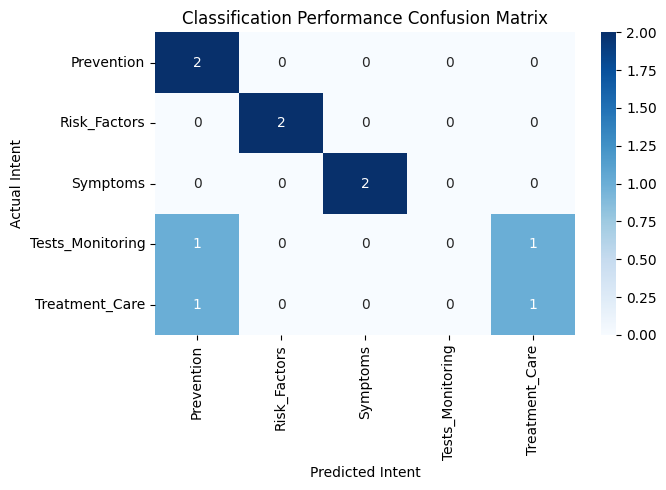

<IPython.core.display.Javascript object>

In [3]:
  !pip install -q gradio

  import re
  import nltk
  import numpy as np
  import pandas as pd
  import matplotlib.pyplot as plt
  import seaborn as sns
  import gradio as gr

  from nltk.corpus import stopwords
  from nltk.tokenize import word_tokenize
  from nltk.stem import WordNetLemmatizer

  from sklearn.feature_extraction.text import TfidfVectorizer
  from sklearn.svm import SVC
  from sklearn.model_selection import train_test_split
  from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

  # Download resources securely, including punkt_tab to resolve the tokenization error
  nltk.download('punkt', quiet=True)
  nltk.download('punkt_tab', quiet=True)
  nltk.download('stopwords', quiet=True)
  nltk.download('wordnet', quiet=True)
  nltk.download('omw-1.4', quiet=True)

  # =====================================================================
  # REQUIREMENT 1: Labelled Corpus (50 queries across 5 intent categories)
  # =====================================================================
  corpus_data = [
      ("What are common warning signs of a heart attack?", "Symptoms"),
      ("Can a heart attack cause pain in the jaw?", "Symptoms"),
      ("Why might someone feel short of breath during a heart problem?", "Symptoms"),
      ("What does chest pressure sometimes feel like during a heart attack?", "Symptoms"),
      ("Can unusual sweating happen with a heart attack?", "Symptoms"),
      ("What are possible signs of heart failure?", "Symptoms"),
      ("Can swelling in the ankles be related to heart problems?", "Symptoms"),
      ("What symptoms can occur with an irregular heartbeat?", "Symptoms"),
      ("What are some early symptoms that should be discussed with a doctor?", "Symptoms"),
      ("Can nausea occur alongside heart attack symptoms?", "Symptoms"),

      ("How can I build a heart-healthy eating routine?", "Prevention"),
      ("What kinds of physical activity support heart health?", "Prevention"),
      ("Why is quitting smoking good for the heart?", "Prevention"),
      ("How can I reduce salt in my daily meals?", "Prevention"),
      ("Does getting enough sleep support cardiovascular health?", "Prevention"),
      ("What are some ways to stay physically active during the week?", "Prevention"),
      ("How can I maintain a healthy weight for my heart?", "Prevention"),
      ("Why are fruits and vegetables included in heart-healthy diets?", "Prevention"),
      ("What daily habits can support healthy blood pressure?", "Prevention"),
      ("How can I make walking part of my weekly routine?", "Prevention"),

      ("Can high blood pressure increase the risk of heart disease?", "Risk_Factors"),
      ("How does high cholesterol affect the arteries?", "Risk_Factors"),
      ("Does diabetes increase cardiovascular risk?", "Risk_Factors"),
      ("Can smoking damage blood vessels?", "Risk_Factors"),
      ("Does family history matter when assessing heart disease risk?", "Risk_Factors"),
      ("How can physical inactivity affect heart health?", "Risk_Factors"),
      ("Can excess body weight contribute to heart disease risk?", "Risk_Factors"),
      ("Does age influence cardiovascular risk?", "Risk_Factors"),
      ("Can secondhand smoke affect cardiovascular health?", "Risk_Factors"),
      ("Why is high blood sugar considered a heart disease risk factor?", "Risk_Factors"),

      ("What information does an electrocardiogram provide?", "Tests_Monitoring"),
      ("What is the purpose of a blood pressure check?", "Tests_Monitoring"),
      ("Why might a clinician request a cholesterol blood test?", "Tests_Monitoring"),
      ("What is an echocardiogram used to examine?", "Tests_Monitoring"),
      ("What happens during a stress test for the heart?", "Tests_Monitoring"),
      ("How is heart rhythm monitored over a longer period?", "Tests_Monitoring"),
      ("What does a coronary angiogram help doctors see?", "Tests_Monitoring"),
      ("Why might a doctor check blood glucose during a heart assessment?", "Tests_Monitoring"),
      ("What is a Holter monitor used for?", "Tests_Monitoring"),
      ("What can a lipid profile tell a healthcare professional?", "Tests_Monitoring"),

      ("What treatments may be used to manage high blood pressure?", "Treatment_Care"),
      ("Why might a clinician prescribe a statin?", "Treatment_Care"),
      ("What is cardiac rehabilitation?", "Treatment_Care"),
      ("What is angioplasty intended to do?", "Treatment_Care"),
      ("Why is follow-up important after a heart procedure?", "Treatment_Care"),
      ("Should someone stop prescribed heart medicine when they feel better?", "Treatment_Care"),
      ("What questions can I ask my doctor about a new heart medicine?", "Treatment_Care"),
      ("How can people remember to take prescribed medicines safely?", "Treatment_Care"),
      ("Why should I discuss side effects with my pharmacist or doctor?", "Treatment_Care"),
      ("Can a doctor recommend different treatment options for heart conditions?", "Treatment_Care"),
  ]

  df = pd.DataFrame(corpus_data, columns=["query", "intent"])

  # =====================================================================
  # REQUIREMENT 2: Hierarchical Taxonomy (4 Major Categories, 2 Subcategories each)
  # =====================================================================
  taxonomy = {
      "Cardiology": {
          "Subcategories": ["Coronary Artery Disease", "Heart Failure"],
          "Description": "Focuses on cardiovascular structure, muscle health, and coronary circulation."
      },
      "Pulmonology": {
          "Subcategories": ["Asthma Care", "Chronic Bronchitis"],
          "Description": "Addresses airway obstruction, ventilation, and oxygenation systems."
      },
      "Endocrinology": {
          "Subcategories": ["Diabetes Mellitus", "Thyroid Dysfunction"],
          "Description": "Manages hormonal regulation, metabolic conditions, and insulin therapy."
      },
      "Neurology": {
          "Subcategories": ["Ischemic Stroke", "Migraine Management"],
          "Description": "Focuses on sensory pathways, cerebral circulation, and nervous networks."
      }
  }

  # =====================================================================
  # REQUIREMENT 3: Domain Ontology (8 Concepts & 10 Relationships)
  # =====================================================================
  ontology_concepts = [
      "Patient", "Doctor", "Symptom", "Diagnosis",
      "Medication", "Treatment", "Risk_Factor", "Test"
  ]

  ontology_relationships = [
      ("Patient", "presents", "Symptom"),
      ("Symptom", "suggests", "Diagnosis"),
      ("Doctor", "diagnoses", "Diagnosis"),
      ("Doctor", "prescribes", "Medication"),
      ("Medication", "manages", "Diagnosis"),
      ("Patient", "undergoes", "Treatment"),
      ("Risk_Factor", "increases_risk_of", "Diagnosis"),
      ("Test", "confirms", "Diagnosis"),
      ("Doctor", "orders", "Test"),
      ("Patient", "manages", "Risk_Factor")
  ]

  # =====================================================================
  # REQUIREMENT 4: Preprocessing Pipeline (Lower, Token, Stopwords, Lemmatizer)
  # =====================================================================
  stop_words = set(stopwords.words('english'))
  lemmatizer = WordNetLemmatizer()

  def preprocess_text(text):
      # 1. Lowercase
      text_lower = text.lower()
      # 2. Safe Tokenization (Fallback to split if nltk tokenization fails)
      try:
          tokens = word_tokenize(text_lower)
      except Exception:
          tokens = re.findall(r'\w+', text_lower)
      # 3. Stopword Removal
      filtered_tokens = [w for w in tokens if w.isalnum() and w not in stop_words]
      # 4. Lemmatization
      lemmatized = [lemmatizer.lemmatize(w) for w in filtered_tokens]
      return " ".join(lemmatized)

  df['cleaned_query'] = df['query'].apply(preprocess_text)

  # =====================================================================
  # REQUIREMENT 5 & 6: TF-IDF Feature Extraction, Classifier & Evaluation
  # =====================================================================
  vectorizer = TfidfVectorizer()
  X = vectorizer.fit_transform(df['cleaned_query'])
  y = df['intent']

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

  # Support Vector Machine for optimal probabilistic boundary classification
  classifier = SVC(kernel='linear', probability=True, random_state=42)
  classifier.fit(X_train, y_train)

  y_pred = classifier.predict(X_test)
  print("=== Performance Classification Evaluation ===")
  print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.2%}\n")
  print(classification_report(y_test, y_pred))

  # Compute Confusion Matrix
  cm = confusion_matrix(y_test, y_pred, labels=classifier.classes_)
  plt.figure(figsize=(7, 5))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
              xticklabels=classifier.classes_, yticklabels=classifier.classes_)
  plt.title("Classification Performance Confusion Matrix")
  plt.ylabel("Actual Intent")
  plt.xlabel("Predicted Intent")
  plt.tight_layout()
  plt.show()

  # Re-train on whole dataset for active production deployment
  final_classifier = SVC(kernel='linear', probability=True, random_state=42)
  final_classifier.fit(X, y)

  # =====================================================================
  # REQUIREMENT 7: Domain-Specific Knowledge Base
  # =====================================================================
  knowledge_base = {
      "Symptoms": "Common clinical warnings indicating heart trouble include radiating chest pain/pressure, jaw stiffness, left arm discomfort, acute shortness of breath, and abnormal peripheral swelling. Please note new developments.",
      "Prevention": "Promote cardiovascular health by restricting high-sodium intake, logging at least 150 minutes of weekly aerobic exercise (e.g., fast walking), avoiding active smoking, and getting consistent restorative sleep.",
      "Risk_Factors": "Major factors escalating cardiovascular disease risk are systemic hypertension, metabolic diabetes, elevated LDL lipids, chronic stress, inactive habits, and family histories.",
      "Tests_Monitoring": "Typical medical tests to monitor performance are 12-lead ECGs for electrical rhythms, routine blood pressure checks, comprehensive serum lipid blood test, Echocardiography scans, and ambulatory Holter monitors.",
      "Treatment_Care": "Common therapies involve structured cardiac rehabilitation programs, pharmacotherapies such as daily statins or beta-blockers, and invasive surgical options like angioplasty. Do not pause any medication without doctor consent."
  }

  # =====================================================================
  # REQUIREMENT 8 & 9: Healthcare Cognitive Assistant & Rule Engine
  # =====================================================================
  class HealthcareCognitiveAssistant:
      def __init__(self, classifier, vectorizer, kb):
          self.classifier = classifier
          self.vectorizer = vectorizer
          self.kb = kb

      def process_query(self, query):
          query_lower = query.lower()

          # Rule 1: Emergency pre-filter (Immediate escalation)
          emergency_keywords = ["chest pain", "unresponsive", "stroke", "dying", "choking", "collapsed", "emergency", "911", "severe bleeding"]
          if any(keyword in query_lower for keyword in emergency_keywords):
              return {
                  "predicted_intent": "Emergency_Urgent",
                  "confidence": 1.0,
                  "rule_applied": "Rule 1: Emergency Keyword Match (Fast-track Escalation)",
                  "response": "EMERGENCY WARNING: Critical distress symptoms detected. Please immediately stop this chat, call 112, or present directly to the closest medical emergency facility."
              }

          # Rule 2: Unsupported Out-of-Domain pre-filter
          unsupported_topics = ["weather", "stock price", "movie", "flight", "hotel", "restaurant", "sports score", "buy tickets"]
          if any(topic in query_lower for topic in unsupported_topics):
              return {
                  "predicted_intent": "None / Out of Domain",
                  "confidence": 0.0,
                  "rule_applied": "Rule 2: Unsupported Domain Query Handler",
                  "response": "I apologize, but I am a Healthcare Cognitive Assistant. I can only assist with cardiovascular symptoms, preventative care, risk factors, clinical diagnostics, and medical treatments."
              }

          # Rule 3: Empty / Noise prompt handler
          cleaned = preprocess_text(query)
          if not cleaned.strip():
              return {
                  "predicted_intent": "None",
                  "confidence": 0.0,
                  "rule_applied": "Rule 3: Noise Input Filtering",
                  "response": "I couldn't identify any clear clinical terminology in your query. Could you please specify your cardiovascular concern?"
              }

          # TF-IDF Mapping & Machine Learning Evaluation
          vec = self.vectorizer.transform([cleaned])
          probabilities = self.classifier.predict_proba(vec)[0]
          max_idx = np.argmax(probabilities)
          confidence = probabilities[max_idx]
          predicted_intent = self.classifier.classes_[max_idx]

          # Rule 4: Low-confidence routing
          CONFIDENCE_THRESHOLD = 0.35
          if confidence < CONFIDENCE_THRESHOLD:
              return {
                  "predicted_intent": predicted_intent,
                  "confidence": float(confidence),
                  "rule_applied": "Rule 4: Low-Confidence Ambiguity Fallback",
                  "response": f"I am not completely certain I understood your query (confidence score: {confidence:.2%}). It seems related to '{predicted_intent}'. Could you please elaborate?"
              }

          # Rule 5: Standard Knowledge Retrieval mapping
          return {
              "predicted_intent": predicted_intent,
              "confidence": float(confidence),
              "rule_applied": "Rule 5: Intent-Specific Clinical Knowledge Base Retrieval",
              "response": self.kb.get(predicted_intent, "No detailed response matches this specific intent.")
          }

  assistant = HealthcareCognitiveAssistant(final_classifier, vectorizer, knowledge_base)

  # =====================================================================
  # REQUIREMENT 10: Interactive Gradio Application with Embedded Test Scenarios
  # =====================================================================
  def bot_interface(message):
      result = assistant.process_query(message)

      metadata = (
          f"### **Clinical Analytics Engine Insights**\n"
          f"* **Classified Intent**: `{result['predicted_intent']}`\n"
          f"* **Classification Confidence**: `{result['confidence']:.2%}`\n"
          f"* **Active Rule Triggered**: `{result['rule_applied']}`\n\n"
          f"---\n"
          f"### **Hierarchical Taxonomy Reference**\n"
      )
      for cat, val in taxonomy.items():
          metadata += f"* **{cat}** (Subcategories: {', '.join(val['Subcategories'])}): *{val['Description']}*\n"

      metadata += "\n---\n### **Clinical Knowledge Ontology Definitions**\n"
      metadata += f"* **Entities**: `{', '.join(ontology_concepts)}`\n"
      metadata += "* **Sample Graph Rules**:\n"
      for sub, pred, obj in ontology_relationships[:5]:
          metadata += f"  - `({sub})` -- **{pred}** --> `({obj})`\n"

      return result['response'], metadata

  demo = gr.Interface(
      fn=bot_interface,
      inputs=gr.Textbox(lines=2, label="Enter Your Patient Query:", placeholder="e.g., What medications should I take to manage high blood pressure?"),
      outputs=[
          gr.Textbox(label="Cognitive Assistant Response:"),
          gr.Markdown(label="Reasoning Logs & Ontology Context")
      ],
      title="🏥 Healthcare Cognitive Assistant Interface",
      description="Interactive System utilizing natural language pipelines, SVM intent recognition, taxonomies, ontologies, and safety reasoning thresholds.",
      examples=[
          ["Can a doctor prescribe a daily statin for cholesterol?"],  # 1. Matches defined intent
          ["What kind of routine physical activities support vascular wellness?"], # 2. Differently worded
          ["Will the weather be hot and sunny tomorrow?"], # 3. Unsupported query
          ["How do we know who is there?"], # 4. Low-confidence query
          ["Help, he has crushing chest pain and has collapsed on the ground!"], # 5. Emergency-related query
          ["What are common warning signs of a heart attack?"],
["How can I maintain a healthy lifestyle for my heart?"],
["Can smoking increase the risk of heart disease?"],
["What is an ECG used for?"],
      ]
  )

  # Deploy internally
  demo.launch(quiet=True, share=False)